# BADMET: Black hole ADaptive Multi-relation Mass Estimation based on Timing Analysis

This notebook takes one observation from the paper's real sample and compares four inference results: three single-indicator measurements and their combination. 

| Measurement | BADMET method | 
|---|---|
| Variability timescale $\tau$ | `add_tau` |
| X-ray luminosity $L_X$ | `add_param` |
| Normalized excess variance $\sigma^2_{\rm NXV}$ | `add_Mparam` |

The final panel compares the three individual posteriors with the joint constraint $p(M_{\rm BH}\mid\tau,L_X,\sigma^2_{\rm NXV})$.

In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "badmet" / "estimator.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from BADMET or one of its subdirectories.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import autograd.numpy as anp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from badmet import MassEstimator

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Select one observation from the paper sample

We use **IRAS 11119+3257**, observation **0881350101**.

In [2]:
data = pd.read_pickle(ROOT / "Paper" / "data" / "dfx_MassEstimated_Real.pkl")
match = data[(data["src_name"] == "IRAS 11119+3257") & (data["obsid"].astype(str) == "0881350101")]
if len(match) != 1:
    raise RuntimeError(f"Expected one matching observation, found {len(match)}.")
source = match.iloc[0]

inputs = pd.DataFrame({
    "measurement": ["Variability timescale", "X-ray luminosity", "Normalized excess variance"],
    "value": [source.log_tau_mle, source.lumin, source.log_sigma2_NXV],
    "measurement error": [np.nan, source.lumin_err, source.log_sigma2_NXV_ERR],
    "unit / scale": ["log10(tau)", "log10(erg/s)", "log10(sigma_NXV^2)"],
})
inputs.style.format({"value": "{:.4f}", "measurement error": lambda x: "—" if pd.isna(x) else f"{x:.4f}"})

,measurement,value,measurement error,unit / scale
0,Variability timescale,4.5227,—,log10(tau)
1,X-ray luminosity,44.0096,0.0103,log10(erg/s)
2,Normalized excess variance,-1.7689,0.1693,log10(sigma_NXV^2)


The timescale likelihood additionally incorporates the observational baseline, cadence, and source redshift. Because BADMET derives the timescale uncertainty from its forward-modelled probability map, the uncertainty associated with the maximum-likelihood DRW timescale estimate is not required as an input.

In [3]:
pd.Series({
    "baseline": source.baseline,
    "number of cadences": source.ncadence,
    "redshift": source.redshift,
}, name="timescale context")

baseline              100200.00000
number of cadences       257.00000
redshift                   0.18758
Name: timescale context, dtype: float64

## 2. Define the three empirical relations

These are the same relations and relation scatters used in the real-data section of `PaperPlot.ipynb`.

In [4]:
def mass_from_nxv(log_sigma2_nxv):
    return -0.94 * (log_sigma2_nxv - anp.log10(0.005)) + 7.41

def expected_lx(log_mass):
    return 0.89 * (log_mass - 8.0) - 0.16 + 44.0

def expected_log_tau(log_mass, redshift):
    return 1.28 * log_mass - 4.37 + anp.log10(1.0 + redshift)

## 3. Infer black hole masses from each indicator and their combination

In [5]:
def add_measurement(estimator, method, row):
    if method == "Timescale":
        estimator.add_tau(
            row.log_tau_mle, row.baseline, row.ncadence,
            expected_log_tau, 0.40, args=[row.redshift], args_err=[0.0],
        )
    elif method == "X-ray luminosity":
        estimator.add_param(row.lumin, row.lumin_err, expected_lx, 0.70)
    elif method == "Excess variance":
        estimator.add_Mparam(
            mass_from_nxv, 0.70,
            args=[row.log_sigma2_NXV], args_err=[row.log_sigma2_NXV_ERR],
        )
    elif method == "Combination":
        estimator.add_tau(
            row.log_tau_mle, row.baseline, row.ncadence,
            expected_log_tau, 0.40, args=[row.redshift], args_err=[0.0],
        )   
        estimator.add_param(row.lumin, row.lumin_err, expected_lx, 0.70)
        estimator.add_Mparam(
            mass_from_nxv, 0.70,
            args=[row.log_sigma2_NXV], args_err=[row.log_sigma2_NXV_ERR],
        )
    else:
        raise ValueError(f"Unknown method: {method}")

methods = ["Timescale", "X-ray luminosity", "Excess variance", "Combination"]
colors = {
    "Timescale": "#E45756",
    "X-ray luminosity": "#F2CF5B", "Excess variance": "#72B7B2",
    "Combination": "#6F4E7C", "Reference mass": "#000000",
}

In [6]:
np.random.seed(42)
samples = {}
for method in methods:
    estimator = MassEstimator()
    add_measurement(estimator, method, source)
    samples[method] = estimator.estimate(
        initial=np.array([source.LOGMBH]), nwalkers=24, nsteps=1200, pool_size=1
    )[:, 0]

100%|██████████████████████████████████████████████████████████████████████████| 1200/1200 [00:04<00:00, 263.73it/s]


## 4. Compare the four posteriors

In [7]:
summary = []
for label, chain in samples.items():
    lo, med, hi = np.percentile(chain, [16, 50, 84])
    summary.append((label, med, med-lo, hi-med))
summary = pd.DataFrame(summary, columns=["method", "median", "-1 sigma", "+1 sigma"])
summary.style.format({"median": "{:.3f}", "-1 sigma": "{:.3f}", "+1 sigma": "{:.3f}"})

,method,median,-1 sigma,+1 sigma
0,Timescale,9.299,1.925,1.846
1,X-ray luminosity,8.195,0.770,0.858
2,Excess variance,6.918,0.719,0.692
3,Combination,7.547,0.474,0.506


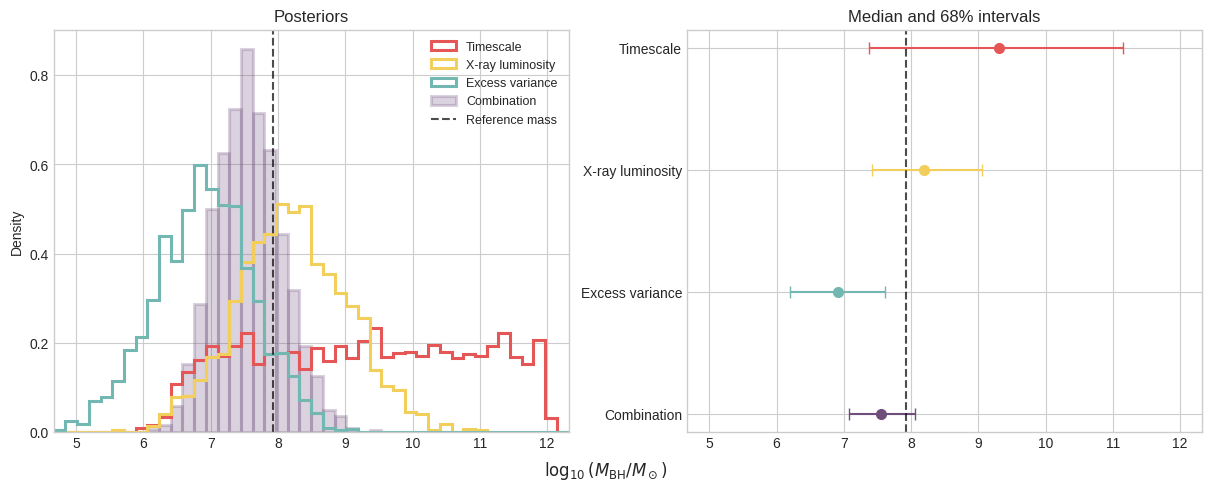

In [8]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

plot_min = min(np.percentile(samples[label], 0.5) for label in methods)
plot_max = max(np.percentile(samples[label], 99.5) for label in methods)
plot_min = min(plot_min, source.LOGMBH)
plot_max = max(plot_max, source.LOGMBH)
padding = 0.05 * (plot_max - plot_min)
plot_range = (plot_min - padding, plot_max + padding)
bins = np.linspace(*plot_range, 45)

for label in methods[:-1]:
    ax.hist(samples[label], bins=bins, density=True, histtype="step", lw=2.2,
            color=colors[label], label=label)
ax.hist(samples["Combination"], bins=bins, density=True, color=colors["Combination"],
        alpha=0.25, edgecolor=colors["Combination"], lw=2.2, label="Combination")
ax.set(ylabel="Density", title="Posteriors", xlim=plot_range)
ax.axvline(source.LOGMBH, color=colors["Reference mass"], ls="--", alpha=0.7,
            label=f"Reference mass")
ax.legend(frameon=False, fontsize=9)

plot_summary = summary.iloc[::-1].reset_index(drop=True)
for y, row in plot_summary.iterrows():
    ax2.errorbar(row["median"], y, xerr=[[row["-1 sigma"]], [row["+1 sigma"]]],
                 fmt="o", ms=7, capsize=4, color=colors[row["method"]])
ax2.set_yticks(range(len(plot_summary)), plot_summary["method"])
ax2.axvline(source.LOGMBH, color=colors["Reference mass"], ls="--", alpha=0.7)
ax2.set(title="Median and 68% intervals", xlim=plot_range)
fig.supxlabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
plt.show()

Although the DRW timescale is likely substantially underestimated, it can still provide a meaningful lower bound on the black hole mass. The combined posterior provides a tighter mass constraint, with the reference mass lying within its 68% credible interval.